# E. coli SCC sizes and cycle-breaking interventions

This notebook measures strongly connected components (SCCs) in the full *E. coli* regulatory network and searches for a small hard-intervention panel that makes every SCC manageable. A hard intervention on gene `v` is modeled as `do(v)`: remove all incoming edges to `v`, retaining the node and its outgoing edges.

The default manageability threshold is a maximum SCC size of 10 nodes. The intervention search is greedy, so it reports a reproducible feasible panel (an upper bound on the true minimum), not a proof of global optimality. The exact minimum is a combinatorial optimization problem.

In [12]:
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
from IPython.display import display

NOTEBOOK_DIR = Path.cwd()
if not (NOTEBOOK_DIR / 'ecoli_full_network_no_small_rna.graphml').exists():
    NOTEBOOK_DIR = NOTEBOOK_DIR / 'notebooks' / 'Ecoli_Analysis_Notebooks'
GRAPH_PATH = NOTEBOOK_DIR / 'ecoli_full_network_no_small_rna.graphml'
MAX_SCC_SIZE = 10

graph = nx.read_graphml(GRAPH_PATH, force_multigraph=False)
graph = nx.DiGraph(graph)
print(f'Graph: {graph.number_of_nodes():,} nodes, {graph.number_of_edges():,} directed edges')
print(f'Manageability threshold: SCC size <= {MAX_SCC_SIZE}')

Graph: 2,976 nodes, 9,211 directed edges
Manageability threshold: SCC size <= 10


## Baseline SCC structure

Total SCCs: 2,895
Nontrivial/cyclic SCCs: 14
Nodes in nontrivial SCCs: 95
Largest SCC: 68 nodes


,number of SCCs
SCC size,
68,1
3,1
2,12
1,2881


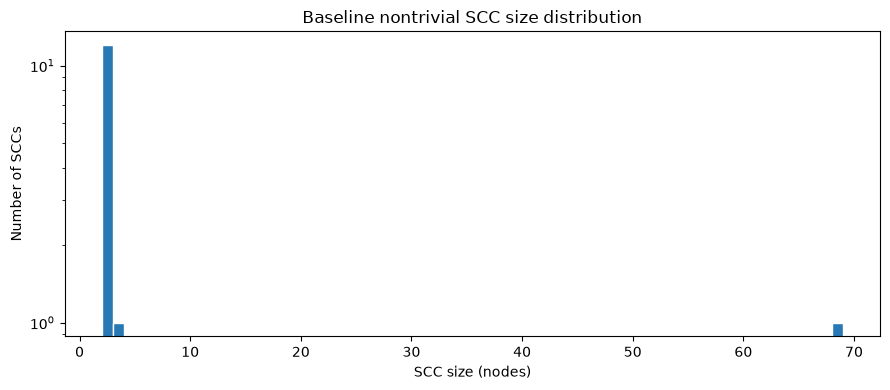

In [13]:
def get_sccs(g):
    return sorted(nx.strongly_connected_components(g), key=lambda component: (-len(component), sorted(component)))

baseline_sccs = get_sccs(graph)
baseline_sizes = pd.Series([len(component) for component in baseline_sccs], name='size')
nontrivial_sccs = [component for component in baseline_sccs if len(component) > 1]

print(f'Total SCCs: {len(baseline_sccs):,}')
print(f'Nontrivial/cyclic SCCs: {len(nontrivial_sccs):,}')
print(f'Nodes in nontrivial SCCs: {sum(map(len, nontrivial_sccs)):,}')
print(f'Largest SCC: {len(baseline_sccs[0])} nodes')
display(baseline_sizes.value_counts().sort_index(ascending=False).rename_axis('SCC size').to_frame('number of SCCs').head(20))

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(baseline_sizes[baseline_sizes > 1], bins=range(2, int(baseline_sizes.max()) + 2), color='#2878B5', edgecolor='white')
ax.set(title='Baseline nontrivial SCC size distribution', xlabel='SCC size (nodes)', ylabel='Number of SCCs')
ax.set_yscale('log')
plt.tight_layout()
plt.show()

In [14]:
largest_scc = baseline_sccs[0]
print('Largest SCC members:')
print(', '.join(sorted(largest_scc)))

Largest SCC members:
acrR, adiY, arcA, argP, argR, bglJ, bolA, cpxR, cra, crp, csgD, cspA, csrA, cytR, deaD, dksA, dnaA, evgA, fis, flhC, flhD, fliA, fliZ, fnr, fur, gadE, gadW, gadX, glnG, hdfR, hns, ihfA, ihfB, leuO, lexA, lldR, lrhA, lrp, matA, mlrA, mqsA, nac, ompR, oxyR, phoB, phoP, qseB, rcsA, rcsB, rpoD, rpoE, rpoH, rpoN, rpoS, rpsA, rstA, rutR, sdiA, slyA, soxR, soxS, stpA, sutR, torR, ydeO, ydiP, yjjQ, zraR


## Greedy intervention search

At each iteration, test hard interventions on each node in the currently oversized SCC. Select the one that gives the smallest resulting maximum SCC; break ties by minimizing the sum of squared nontrivial SCC sizes, then by gene name. Repeat until all SCCs are at or below the configured threshold. Because candidates are restricted to the current largest oversized SCC, this is a tractable heuristic rather than an exact minimum solver.

In [15]:
def apply_hard_interventions(g, targets):
    intervened = g.copy()
    for target in targets:
        intervened.remove_edges_from(list(intervened.in_edges(target)))
    return intervened

def scc_objective(g):
    sizes = [len(component) for component in get_sccs(g)]
    return max(sizes, default=0), sum(size**2 for size in sizes if size > 1), sizes

interventions = []
current_graph = graph.copy()
history = []

while True:
    current_sccs = get_sccs(current_graph)
    oversized = next((component for component in current_sccs if len(component) > MAX_SCC_SIZE), None)
    if oversized is None:
        break

    candidates = []
    for gene in sorted(oversized):
        candidate_graph = apply_hard_interventions(current_graph, [gene])
        max_size, squared_size, sizes = scc_objective(candidate_graph)
        candidates.append(((max_size, squared_size, gene), gene, candidate_graph, sizes))

    _, selected_gene, current_graph, resulting_sizes = min(candidates, key=lambda item: item[0])
    interventions.append(selected_gene)
    history.append({
        'step': len(interventions),
        'intervention': selected_gene,
        'incoming_edges_removed': graph.in_degree(selected_gene),
        'largest_scc_after': max(resulting_sizes, default=0),
        'nontrivial_sccs_after': sum(size > 1 for size in resulting_sizes),
    })
intervention_table = pd.DataFrame(history)
final_sccs = get_sccs(current_graph)
final_sizes = [len(component) for component in final_sccs]
assert max(final_sizes, default=0) <= MAX_SCC_SIZE
print(f'Greedy feasible intervention count: {len(interventions)}')
print('Panel:', ', '.join(interventions))
print(f'Largest SCC after interventions: {max(final_sizes, default=0)}')
print(f'Nontrivial SCCs after interventions: {sum(size > 1 for size in final_sizes)}')
display(intervention_table)

Greedy feasible intervention count: 6
Panel: gadE, gadX, fur, rpoH, rpoD, nac
Largest SCC after interventions: 9
Nontrivial SCCs after interventions: 19


,step,intervention,incoming_edges_removed,largest_scc_after,nontrivial_sccs_after
0,1,gadE,14,49,16
1,2,gadX,17,39,16
2,3,fur,5,33,16
3,4,rpoH,11,27,16
4,5,rpoD,5,23,16
5,6,nac,6,9,19


,stage,interventions_so_far,largest_scc
0,Baseline,0,68
1,After gadE,1,49
2,After gadX,2,39
3,After fur,3,33
4,After rpoH,4,27
5,After rpoD,5,23
6,After nac,6,9


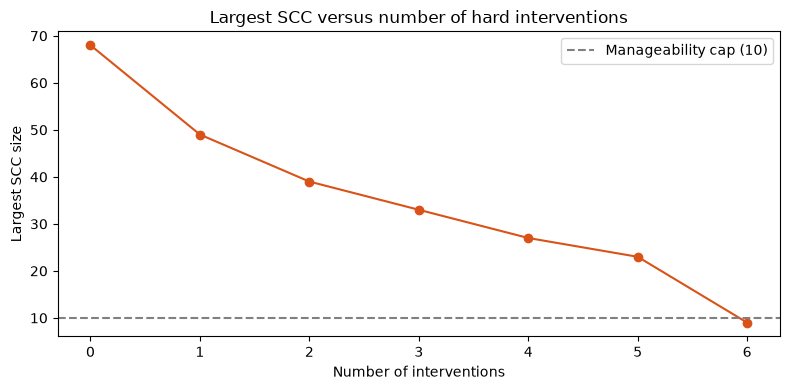

In [16]:
comparison = pd.DataFrame({
    'stage': ['Baseline'] + [f'After {row.intervention}' for row in intervention_table.itertuples()],
    'interventions_so_far': [0] + list(range(1, len(interventions) + 1)),
    'largest_scc': [len(baseline_sccs[0])] + list(intervention_table['largest_scc_after']),
})
display(comparison)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(comparison['interventions_so_far'], comparison['largest_scc'], marker='o', color='#D95319')
ax.axhline(MAX_SCC_SIZE, color='gray', linestyle='--', label=f'Manageability cap ({MAX_SCC_SIZE})')
ax.set(title='Largest SCC versus number of hard interventions', xlabel='Number of interventions', ylabel='Largest SCC size')
ax.set_xticks(comparison['interventions_so_far'])
ax.legend()
plt.tight_layout()
plt.show()

## DAG acyclification and parent-count / CPT complexity

The `dag` acyclification replaces every cyclic SCC with a complete DAG. One fixed alphabetical node order is used at every intervention stage so the comparison does not confound intervention effects with different within-SCC DAG orientations. Edges entering a cyclic SCC are expanded to all its members by the acyclification definition. We count directed parents in the DAG component; any undirected edges of the acyclified mixed graph are excluded.

For a discrete node with `r` states and `p` parents, a full CPT has `r**p` parent configurations and `r**p * (r - 1)` free parameters. The default binary CPT budget is 1,024 rows (at most 10 parents). Change the state count or budget below to match the intended representation. The storage estimate assumes binary nodes, one `uint16` value per parent configuration, and quantization `q = round(p * 65535)` with decoding `q / 65535`. This provides 65,536 probability levels, not 16 decimal digits.

In [17]:
from nocap.acyclification import acyclification
from nocap.cyclic_single_door import nx_digraph_to_y0

CPT_MAX_PARENTS = MAX_SCC_SIZE
CPT_STATE_COUNT = 2
CPT_ROW_BUDGET = CPT_STATE_COUNT ** CPT_MAX_PARENTS

def dag_acyclify(g):
    mixed_graph = nx_digraph_to_y0(g)
    return acyclification(
        mixed_graph,
        acyclification_type='dag'
    ).directed

stages = [('Baseline', graph)] + [
    (f'After {gene}', apply_hard_interventions(graph, interventions[:step]))
    for step, gene in enumerate(interventions, start=1)
]
parent_counts_by_stage = {}
parent_summary = []

for stage_name, stage_graph in stages:
    dag = dag_acyclify(stage_graph)
    assert nx.is_directed_acyclic_graph(dag)
    parent_counts = pd.Series(
        {node.name: degree for node, degree in dag.in_degree()},
        name=stage_name,
    ).reindex(sorted(graph.nodes), fill_value=0)
    parent_counts_by_stage[stage_name] = parent_counts
    parent_summary.append({
        'stage': stage_name,
        'mean_parents': parent_counts.mean(),
        'median_parents': parent_counts.median(),
        'p90_parents': parent_counts.quantile(0.90),
        'p95_parents': parent_counts.quantile(0.95),
        'max_parents': int(parent_counts.max()),
        'total_directed_parent_links': int(parent_counts.sum()),
        f'nodes_over_{CPT_MAX_PARENTS}_parents': int((parent_counts > CPT_MAX_PARENTS).sum()),
        'max_binary_cpt_rows': CPT_STATE_COUNT ** int(parent_counts.max()),
        f'nodes_within_{CPT_ROW_BUDGET}_row_budget': int((parent_counts <= CPT_MAX_PARENTS).sum()),
    })

parent_summary_df = pd.DataFrame(parent_summary)
display(parent_summary_df.round(2))

parent_frequency = pd.DataFrame({
    stage: counts.value_counts().sort_index()
    for stage, counts in parent_counts_by_stage.items()
}).fillna(0).astype(int)
display(parent_frequency.rename_axis('Number of parents'))

,stage,mean_parents,median_parents,p90_parents,p95_parents,max_parents,total_directed_parent_links,nodes_over_10_parents,max_binary_cpt_rows,nodes_within_1024_row_budget
0,Baseline,3.87,2.0,7.0,9.0,75,11528,98,37778931862957161709568,2878
1,After gadE,3.51,2.0,7.0,8.0,55,10457,84,36028797018963968,2892
2,After gadX,3.37,2.0,7.0,8.0,46,10028,76,70368744177664,2900
3,After fur,3.29,2.0,6.0,8.0,40,9788,70,1099511627776,2906
4,After rpoH,3.21,2.0,6.0,8.0,34,9550,63,17179869184,2913
5,After rpoD,3.19,2.0,6.0,8.0,34,9496,62,17179869184,2914
6,After nac,3.09,2.0,6.0,8.0,34,9191,48,17179869184,2928


,Baseline,After gadE,After gadX,After fur,After rpoH,After rpoD,After nac
Number of parents,,,,,,,
0,62,63,64,65,66,67,68
1,837,840,842,842,843,846,847
2,668,671,674,674,675,675,678
3,446,446,446,448,450,450,452
4,297,300,302,303,303,303,303
...,...,...,...,...,...,...,...
71,1,0,0,0,0,0,0
72,1,0,0,0,0,0,0
73,1,0,0,0,0,0,0


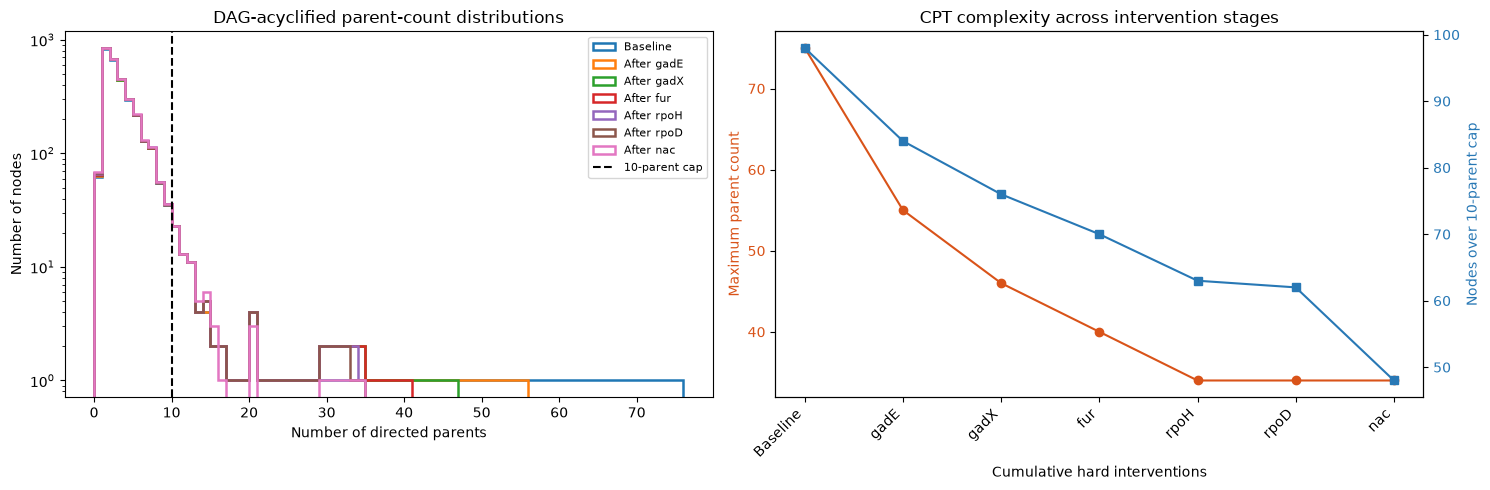

Binary CPT row budget: 1,024 (<= 10 parents)
Largest binary CPT at baseline: 37,778,931,862,957,161,709,568 parent configurations
Largest binary CPT after panel: 17,179,869,184 parent configurations
Post-intervention dense CPT storage (actual parent counts): 135,305,948,968 bytes
  = 126.01 GiB (135.31 GB)
Largest individual CPT: 68,719,476,736 bytes = 64.00 GiB
Estimate includes 4 bytes per row for binary CPTs; excludes graph, indexing, and runtime overhead.


,parents,parent_configurations,byte_per_prob
mlrA,34,17179869184,68719476736
fliZ,33,8589934592,34359738368
fliA,32,4294967296,17179869184
flhD,31,2147483648,8589934592
flhC,30,1073741824,4294967296
csgD,29,536870912,2147483648
csgE,20,1048576,4194304
csgF,20,1048576,4194304
csgG,20,1048576,4194304
gltF,16,65536,262144


,baseline_parents,after_panel_parents,parent_reduction,binary_cpt_rows_after_panel
mlrA,47,34,13,17179869184
fliZ,30,33,-3,8589934592
fliA,29,32,-3,4294967296
flhD,28,31,-3,2147483648
flhC,27,30,-3,1073741824
csgD,18,29,-11,536870912
csgE,20,20,0,1048576
csgF,20,20,0,1048576
csgG,20,20,0,1048576
gltF,16,16,0,65536


Nodes still above the 10-parent budget: 48
Total DAG parent links: 11,528 -> 9,191 (20.3% reduction)
Mean parents per node: 3.87 -> 3.09
Nodes over 10 parents: 98 -> 48
Maximum parents: 75 -> 34
Parent counts can increase for individual nodes: DAG acyclification expands edges entering cyclic SCCs to all SCC members.


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for stage, counts in parent_counts_by_stage.items():
    axes[0].hist(counts, bins=range(0, int(counts.max()) + 2), histtype='step', linewidth=1.8, label=stage)
axes[0].axvline(CPT_MAX_PARENTS, color='black', linestyle='--', label=f'{CPT_MAX_PARENTS}-parent cap')
axes[0].set(title='DAG-acyclified parent-count distributions', xlabel='Number of directed parents', ylabel='Number of nodes', yscale='log')
axes[0].legend(fontsize=8)

summary_by_stage = parent_summary_df.set_index('stage')
stage_positions = range(len(stages))
axes[1].plot(stage_positions, summary_by_stage['max_parents'], marker='o', color='#D95319')
axes[1].set_ylabel('Maximum parent count', color='#D95319')
axes[1].tick_params(axis='y', labelcolor='#D95319')
over_cap_ax = axes[1].twinx()
over_cap_ax.plot(
    stage_positions,
    summary_by_stage[f'nodes_over_{CPT_MAX_PARENTS}_parents'],
    marker='s',
    color='#2878B5',
    label=f'Nodes over {CPT_MAX_PARENTS} parents',
)
over_cap_ax.set_ylabel(f'Nodes over {CPT_MAX_PARENTS}-parent cap', color='#2878B5')
over_cap_ax.tick_params(axis='y', labelcolor='#2878B5')
axes[1].set(title='CPT complexity across intervention stages', xlabel='Cumulative hard interventions')
axes[1].set_xticks(list(stage_positions), [name.replace('After ', '') for name, _ in stages], rotation=45, ha='right')
plt.tight_layout()
plt.show()

print(f'Binary CPT row budget: {CPT_ROW_BUDGET:,} (<= {CPT_MAX_PARENTS} parents)')
print(f'Largest binary CPT at baseline: {CPT_STATE_COUNT ** int(parent_counts_by_stage["Baseline"].max()):,} parent configurations')
print(f'Largest binary CPT after panel: {CPT_STATE_COUNT ** int(parent_counts_by_stage[stages[-1][0]].max()):,} parent configurations')

final_parent_counts = parent_counts_by_stage[stages[-1][0]]
baseline_parent_counts = parent_counts_by_stage['Baseline']
BYTES_PER_PROB = 4
cpt_storage = pd.DataFrame({
    'parents': final_parent_counts.astype(int),
    'parent_configurations': [CPT_STATE_COUNT ** int(count) for count in final_parent_counts],
})
cpt_storage['byte_per_prob'] = cpt_storage['parent_configurations'] * BYTES_PER_PROB
cpt_storage = cpt_storage.sort_values('byte_per_prob', ascending=False)
total_cpt_bytes = int(cpt_storage['byte_per_prob'].sum())
largest_cpt_bytes = int(cpt_storage['byte_per_prob'].max())
print(f'Post-intervention dense CPT storage (actual parent counts): {total_cpt_bytes:,} bytes')
print(f'  = {total_cpt_bytes / 2**30:,.2f} GiB ({total_cpt_bytes / 10**9:,.2f} GB)')
print(f'Largest individual CPT: {largest_cpt_bytes:,} bytes = {largest_cpt_bytes / 2**30:,.2f} GiB')
print(f'Estimate includes {BYTES_PER_PROB} bytes per row for binary CPTs; excludes graph, indexing, and runtime overhead.')
display(cpt_storage.head(10))
burden_comparison = pd.DataFrame({
    'baseline_parents': baseline_parent_counts,
    'after_panel_parents': final_parent_counts,
    'parent_reduction': baseline_parent_counts - final_parent_counts,
    'binary_cpt_rows_after_panel': [CPT_STATE_COUNT ** int(count) for count in final_parent_counts],
}).sort_values('after_panel_parents', ascending=False)
display(burden_comparison.head(15))
print(f'Nodes still above the {CPT_MAX_PARENTS}-parent budget: {(final_parent_counts > CPT_MAX_PARENTS).sum()}')
print(f'Total DAG parent links: {baseline_parent_counts.sum():,} -> {final_parent_counts.sum():,} ({100 * (baseline_parent_counts.sum() - final_parent_counts.sum()) / baseline_parent_counts.sum():.1f}% reduction)')
print(f'Mean parents per node: {baseline_parent_counts.mean():.2f} -> {final_parent_counts.mean():.2f}')
print(f'Nodes over {CPT_MAX_PARENTS} parents: {(baseline_parent_counts > CPT_MAX_PARENTS).sum()} -> {(final_parent_counts > CPT_MAX_PARENTS).sum()}')
print(f'Maximum parents: {baseline_parent_counts.max()} -> {final_parent_counts.max()}')
print('Parent counts can increase for individual nodes: DAG acyclification expands edges entering cyclic SCCs to all SCC members.')